# 16 — LSTM with attention, and autoencoder embeddings, for forecasting

Plan: `docs/plan_attention_ae.md`. Code: `scripts/attn_forecast.py`. Results: `results/attention/`.

**Question.** Does attention over the input window, or a learned embedding of the shots (autoencoder), forecast the
charge h shots ahead better than the GRU and the ridge of `feature_forecast.py`? What do the attention weights show?

**Setting** — identical to notebook 14 / 15 so the numbers compare: `results/datasets_aligned`, robust preparation,
pooled per regime, inputs known after shot t − h as a window of L = 64 shots (29 inputs: BCM history relative to the
9-shot mean, instrument fast and slow parts, flags), target log Q[t] − log(9-shot mean up to t − h), zero-initialised
output (untrained = baseline), L1 loss, early stopping on validation, 3 seeds averaged, scored on the last 10 %.

| Variant | What it is |
|---|---|
| `lstm` | LSTM (64), last hidden state |
| `lstm_additive` | + Bahdanau additive attention over the window (query = last state) |
| `lstm_general` | + Luong bilinear attention |
| `lstm_mha` | + 4-head attention with learned positional embedding |
| `lstm_self` | + one transformer self-attention block over the LSTM outputs |
| `lstm_vsn_additive` | per-step variable-selection softmax over the inputs (TFT-like), then additive attention |
| `ae_frozen` | per-shot MLP autoencoder 29 → 8, pretrained, frozen; LSTM + additive attention on the codes |
| `ae_joint` | same, trained jointly: L1(forecast) + 0.5 · MSE(reconstruction) |
| `seq_ae` | LSTM sequence autoencoder pretrained on the window, fine-tuned with a forecast head on its 16-d code |

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

In [2]:
A = pd.concat([pd.read_csv(p) for p in sorted((R / "attention").glob("scores_L64_h*.csv"))])
ref = pd.read_csv(R / "aligned/feature_forecast/scores.csv")
ref = ref[ref.h.isin(A.h.unique())]
allm = pd.concat([A[["h", "segment", "regime", "model", "mae_nC", "mae_pct"]],
                  ref[["h", "segment", "regime", "model", "mae_nC", "mae_pct"]]])
base = allm[allm.model == "mean9 (baseline)"].set_index(["h", "segment"]).mae_nC
allm["vs_mean9_pct"] = 100 * (allm.mae_nC / base.reindex(pd.MultiIndex.from_frame(allm[["h", "segment"]])).values - 1)
VARS = ["lstm", "lstm_additive", "lstm_general", "lstm_mha", "lstm_self", "lstm_vsn_additive", "ae_frozen", "ae_joint", "seq_ae"]
REFS = ["ridge, all", "gru L=32, all"]
tab = allm[allm.model.isin(VARS + REFS)].pivot_table(index=["h", "model"], columns="segment", values="vs_mean9_pct")[SEG_ORDER]
tab.round(1)

segment                 0     3    4    5    1    6    7
h  model                                                
1  ae_frozen         -6.3  -4.6 -0.5 -2.4 -3.8 -4.1 -5.6
   ae_joint          -6.5  -4.9 -0.7 -2.5 -4.0 -4.1 -5.3
   gru L=32, all     -6.6  -4.4 -1.5 -2.6 -4.4 -3.1 -5.3
   lstm              -5.8  -4.7 -1.9 -2.7 -4.0 -2.8 -5.2
   lstm_additive     -6.5  -5.0 -1.8 -2.7 -4.1 -3.2 -5.3
   lstm_general      -6.4  -5.1 -1.6 -2.7 -4.1 -3.2 -5.3
   lstm_mha          -6.5  -5.1 -1.7 -2.7 -4.1 -3.3 -5.3
   lstm_self         -5.9  -4.6 -1.7 -2.6 -3.9 -2.4 -4.6
   lstm_vsn_additive -6.3  -4.6 -1.5 -2.6 -4.0 -2.9 -5.1
   ridge, all        -6.4  -4.9 -1.1 -2.7 -4.0 -4.3 -4.2
   seq_ae            -6.3  -4.6 -0.4 -2.7 -3.8 -3.2 -4.9
5  ae_frozen         -6.0  -6.0 -1.3 -2.1 -4.3 -5.9 -0.8
   ae_joint          -6.7  -6.2 -1.4 -2.8 -4.6 -6.7 -0.9
   gru L=32, all     -7.0  -5.9 -2.2 -2.8 -5.1 -6.0 -2.2
   lstm              -6.9  -5.5 -2.2 -2.8 -4.8 -6.0 -1.6
   lstm_additive     -7.0  -6.2 -2.2 -2.6 -4.8 -5.9 -1.6
   lstm_general      -7.0  -6.5 -2.2 -2.6 -4.9 -6.2 -1.5
   lstm_mha          -6.9  -6.2 -2.5 -2.8 -4.7 -6.5 -1.9
   lstm_self         -6.9  -5.8 -2.6 -2.7 -4.4 -7.8 -2.1
   lstm_vsn_additive -7.0  -5.5 -2.3 -2.7 -4.8 -6.6 -2.0
   ridge, all        -7.1  -6.0 -2.3 -2.8 -4.5 -7.3 -1.6
   seq_ae            -6.3  -5.5 -2.1 -2.5 -4.6 -6.6 -1.8
10 ae_frozen         -6.4  -6.7 -2.4 -1.3 -2.9 -8.5 -0.9
   ae_joint          -6.4  -6.9 -3.2 -1.7 -3.1 -8.9 -1.2
   gru L=32, all     -5.9  -6.7 -4.2 -2.0 -3.2 -7.4 -1.3
   lstm              -6.4  -6.5 -3.5 -2.2 -3.5 -6.9 -1.2
   lstm_additive     -6.2  -7.1 -4.3 -2.3 -3.3 -7.4 -1.2
   lstm_general      -6.3  -7.1 -4.2 -2.3 -3.3 -7.4 -1.2
   lstm_mha          -6.4  -7.0 -4.0 -2.4 -3.3 -7.6 -1.3
   lstm_self         -6.3  -5.1 -4.2 -2.3 -3.3 -9.2 -1.8
   lstm_vsn_additive -6.3  -5.8 -3.7 -2.3 -3.3 -7.6 -0.8
   ridge, all        -7.2  -6.5 -3.0 -1.5 -2.8 -9.3 -0.7
   seq_ae            -6.5  -6.3 -3.1 -2.4 -2.7 -9.2 -0.4
20 ae_frozen         -6.5  -9.7 -4.6 -1.6 -1.6 -7.4 -3.8
   ae_joint          -6.6  -9.6 -5.1 -1.2 -2.0 -7.4 -4.0
   gru L=32, all     -6.9  -7.1 -3.7 -2.2 -1.6 -7.4 -3.4
   lstm              -6.5 -10.2 -5.4 -1.6 -2.4 -8.2 -4.2
   lstm_additive     -7.2 -10.5 -5.6 -0.8 -2.6 -8.3 -4.4
   lstm_general      -7.3  -9.6 -5.7 -1.6 -2.6 -8.3 -4.3
   lstm_mha          -7.5  -8.8 -5.5 -1.5 -2.4 -8.6 -4.5
   lstm_self         -6.6  -6.3 -4.5 -1.5 -2.6 -7.4 -4.4
   lstm_vsn_additive -6.5  -8.7 -4.5 -0.7 -2.6 -8.8 -4.2
   ridge, all        -6.9 -10.5 -3.9 -1.8 -0.5 -6.7 -3.3
   seq_ae            -7.5  -9.9 -5.2 -1.5 -1.5 -7.1 -2.6
50 ae_frozen         -3.1 -10.8 -4.0 -2.6 -1.5 -5.4  0.0
   ae_joint          -4.0 -11.5 -4.6 -2.3 -2.5 -5.2  0.4
   gru L=32, all     -1.1  -9.9 -9.1 -4.0 -1.7 -4.4 -2.5
   lstm              -2.7 -11.0 -7.7 -1.4 -2.6 -5.8 -2.3
   lstm_additive     -2.3 -10.8 -5.8 -3.4 -3.4 -4.6 -2.9
   lstm_general      -3.4  -8.9 -5.7 -2.6 -3.4 -4.5 -3.0
   lstm_mha          -3.8  -7.8 -5.3 -2.7 -2.7 -4.4 -1.9
   lstm_self         -3.3  -4.6 -4.9 -4.1 -3.0 -4.9 -2.4
   lstm_vsn_additive -2.6 -10.4 -5.9 -2.7 -3.7 -3.1 -2.7
   ridge, all        -3.9 -12.0 -6.5 -2.1  0.4 -3.6 -1.2
   seq_ae            -3.5  -8.2 -6.1 -4.4 -1.6 -5.5 -0.3

## 1. Benchmark against the 9-shot mean, the ridge and the GRU

Change of test MAE against the 9-shot mean (%, negative = better), averaged over the 7 segments, per horizon.

/tmp/ipykernel_3914769/3837407142.py:5: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(mean_over.columns, mean_over.loc[m], "o-", label=m, **style)


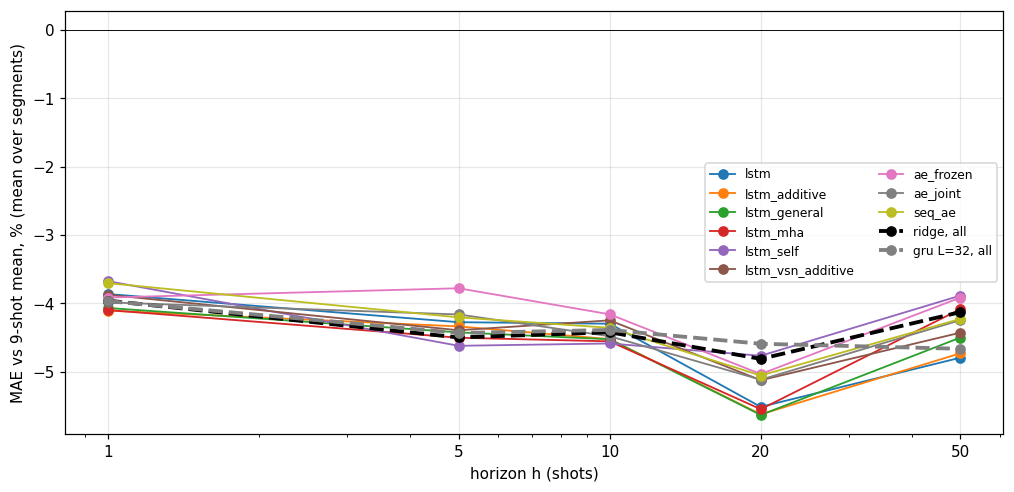

h,1,5,10,20,50
model,,,,,
ae_frozen,-3.92,-3.78,-4.16,-5.03,-3.92
ae_joint,-3.99,-4.16,-4.48,-5.12,-4.25
"gru L=32, all",-3.97,-4.43,-4.39,-4.59,-4.67
lstm,-3.86,-4.28,-4.30,-5.52,-4.80
lstm_additive,-4.11,-4.34,-4.52,-5.62,-4.73
lstm_general,-4.07,-4.42,-4.53,-5.63,-4.50
lstm_mha,-4.10,-4.50,-4.56,-5.55,-4.08
lstm_self,-3.68,-4.62,-4.59,-4.77,-3.89
lstm_vsn_additive,-3.87,-4.39,-4.25,-5.13,-4.43


In [3]:
mean_over = allm[allm.model.isin(VARS + REFS)].groupby(["model", "h"]).vs_mean9_pct.mean().unstack()
fig, ax = plt.subplots(figsize=(11, 5))
for m in VARS + REFS:
    style = dict(lw=2.5, ls="--", color="k" if m == "ridge, all" else "0.5") if m in REFS else dict(lw=1.2)
    ax.plot(mean_over.columns, mean_over.loc[m], "o-", label=m, **style)
ax.set_xscale("log"); ax.set_xticks(mean_over.columns, mean_over.columns); ax.set_xlabel("horizon h (shots)")
ax.set_ylabel("MAE vs 9-shot mean, % (mean over segments)"); ax.legend(ncol=2, fontsize=8); ax.axhline(0, color="k", lw=0.6)
plt.show()
mean_over.round(2)

In [4]:
rank = allm[allm.model.isin(VARS + REFS)].copy()
rank["rank"] = rank.groupby(["h", "segment"]).mae_nC.rank()
r = rank.groupby("model")["rank"].agg(["mean", "std"]).sort_values("mean")
r["wins (best of 11)"] = rank[rank["rank"] == 1].groupby("model").size().reindex(r.index).fillna(0).astype(int)
r.round(2)

,mean,std,wins (best of 11)
model,,,
lstm_mha,4.34,2.40,3
lstm_general,4.60,2.58,3
lstm_additive,4.71,2.82,3
lstm,5.89,2.84,3
"gru L=32, all",6.11,3.40,6
lstm_self,6.23,3.23,3
"ridge, all",6.23,3.82,7
lstm_vsn_additive,6.49,2.92,2
ae_joint,6.63,2.66,1


## 2. Is the best attention / autoencoder variant significantly different from the GRU and the ridge?

Circular block bootstrap of the test shots (50-shot blocks, 2000 resamples), as in `uncertainty_regimes.py`.

In [5]:
from uncertainty_regimes import boot_gain
segs, names = load(R.parent / "results/datasets_aligned", robust=5)
P = {}
for p in sorted((R / "attention").glob("predictions_L64_h*.npz")):
    z = np.load(p); P.update({k: z[k] for k in z.files})
Fr = np.load(R / "aligned/feature_forecast/predictions.npz")
best_var = r.index[[m in VARS for m in r.index]][0]
rng = np.random.default_rng(0)
rows = []
for h in sorted(A.h.unique()):
    for s in SEG_ORDER:
        g = segs[s]; te = g["test"]
        k = f"h{h}|seg{s}|{best_var}"
        if k not in P: continue
        e_best = np.abs(P[k][te] - g["y"][te])
        for refm in ("gru L=32, all", "ridge, all", "lstm"):
            ref_pred = Fr[f"h{h}|seg{s}|{refm}"] if refm in REFS else P[f"h{h}|seg{s}|{refm}"]
            ok = np.isfinite(ref_pred[te]) & np.isfinite(P[k][te])
            g0, lo, hi = boot_gain(np.abs(ref_pred[te] - g["y"][te])[ok], e_best[ok], rng)
            rows.append({"h": h, "segment": s, "vs": refm, "cell": f"{g0:+.1f} [{lo:+.1f}, {hi:+.1f}]" + ("" if lo > 0 or hi < 0 else " ns"),
                         "significant better": lo > 0, "significant worse": hi < 0})
sig = pd.DataFrame(rows)
print("best variant by mean rank:", best_var)
display(sig.pivot_table(index=["vs", "h"], columns="segment", values="cell", aggfunc="first")[SEG_ORDER])
sig.groupby("vs")[["significant better", "significant worse"]].mean().round(2)

best variant by mean rank: lstm_mha


segment                              0                      3  \
vs            h                                                 
gru L=32, all 1   -0.0 [-0.5, +0.4] ns   +0.7 [-0.6, +2.7] ns   
              5   -0.1 [-0.8, +0.6] ns   +0.4 [-1.3, +2.5] ns   
              10  +0.5 [-0.5, +1.5] ns   +0.3 [-0.6, +1.6] ns   
              20  +0.7 [-0.9, +2.4] ns   +1.9 [-3.0, +7.0] ns   
              50     +2.8 [+1.2, +4.4]   -2.4 [-9.7, +2.0] ns   
lstm          1      +0.8 [+0.1, +1.3]   +0.4 [-0.5, +1.7] ns   
              5   -0.0 [-0.8, +0.7] ns   +0.8 [-0.5, +2.4] ns   
              10  +0.0 [-0.5, +0.7] ns   +0.5 [-0.2, +1.2] ns   
              20     +1.1 [+0.4, +1.7]   -1.6 [-5.2, +0.7] ns   
              50  +1.2 [-0.5, +2.8] ns  -3.7 [-11.1, +1.0] ns   
ridge, all    1   +0.1 [-1.3, +1.4] ns   +0.1 [-1.6, +2.4] ns   
              5   -0.2 [-1.1, +0.7] ns   +0.2 [-1.5, +2.2] ns   
              10  -0.9 [-1.8, +0.1] ns   +0.5 [-0.8, +1.7] ns   
              20  +0.7 [-0.6, +2.2] ns   -1.9 [-5.9, +1.2] ns   
              50  -0.1 [-1.7, +1.6] ns  -4.9 [-14.4, +1.3] ns   

segment                               4                     5  \
vs            h                                                 
gru L=32, all 1    +0.3 [-0.5, +1.1] ns  +0.1 [-0.2, +0.4] ns   
              5    +0.3 [-0.6, +1.3] ns  +0.0 [-0.3, +0.4] ns   
              10   -0.2 [-1.0, +0.4] ns  +0.4 [-0.1, +1.0] ns   
              20   +1.9 [-3.2, +5.9] ns  -0.7 [-1.6, +0.3] ns   
              50  -4.2 [-12.2, +2.1] ns  -1.3 [-5.0, +2.1] ns   
lstm          1    -0.2 [-0.6, +0.3] ns  +0.0 [-0.0, +0.0] ns   
              5    +0.3 [-0.4, +0.9] ns  +0.0 [-0.1, +0.2] ns   
              10   +0.6 [-0.2, +1.3] ns  +0.2 [-0.1, +0.5] ns   
              20   +0.1 [-2.5, +2.2] ns  -0.1 [-1.0, +0.7] ns   
              50   -2.7 [-9.6, +2.9] ns  +1.3 [-4.0, +6.5] ns   
ridge, all    1    +0.6 [-0.5, +1.8] ns  -0.0 [-0.7, +0.7] ns   
              5    +0.3 [-1.0, +1.6] ns  +0.0 [-0.8, +1.0] ns   
              10   +1.0 [-0.5, +3.0] ns  +0.9 [-0.3, +2.0] ns   
              20   +1.6 [-1.3, +4.1] ns  -0.3 [-1.8, +1.2] ns   
              50   -1.3 [-6.0, +3.0] ns  +0.6 [-3.2, +4.2] ns   

segment                              1                     6  \
vs            h                                                
gru L=32, all 1   -0.3 [-0.8, +0.0] ns  +0.2 [-0.7, +1.1] ns   
              5   -0.4 [-1.0, +0.2] ns  +0.6 [-0.8, +1.7] ns   
              10  +0.1 [-0.5, +0.8] ns  +0.2 [-0.8, +1.1] ns   
              20     +0.8 [+0.1, +1.5]     +1.3 [+0.4, +2.1]   
              50  +1.1 [-0.9, +3.0] ns  +0.0 [-3.3, +3.7] ns   
lstm          1   +0.1 [-0.2, +0.4] ns  +0.5 [-0.2, +1.3] ns   
              5   -0.1 [-0.6, +0.4] ns  +0.5 [-0.3, +1.3] ns   
              10  -0.2 [-0.7, +0.4] ns     +0.8 [+0.2, +1.3]   
              20  -0.1 [-0.8, +0.6] ns  +0.4 [-0.8, +1.4] ns   
              50  +0.1 [-1.5, +1.6] ns  -1.5 [-3.8, +0.9] ns   
ridge, all    1   +0.1 [-0.5, +0.7] ns  -1.1 [-3.0, +0.4] ns   
              5   +0.2 [-0.7, +1.1] ns  -0.9 [-3.8, +1.9] ns   
              10  +0.5 [-0.6, +1.7] ns     -1.9 [-3.6, -0.2]   
              20     +1.8 [+0.4, +3.2]     +2.1 [+0.4, +3.8]   
              50     +3.1 [+1.2, +5.0]  +0.9 [-0.1, +1.9] ns   

segment                              7  
vs            h                         
gru L=32, all 1   +0.0 [-0.5, +0.4] ns  
              5   -0.3 [-1.0, +0.3] ns  
              10  -0.0 [-0.6, +0.5] ns  
              20     +1.2 [+0.3, +1.9]  
              50  -0.6 [-2.3, +0.5] ns  
lstm          1   +0.2 [-0.3, +0.6] ns  
              5   +0.3 [-0.4, +0.7] ns  
              10  +0.1 [-0.4, +0.8] ns  
              20  +0.4 [-0.0, +0.9] ns  
              50  -0.4 [-1.6, +1.2] ns  
ridge, all    1      +1.2 [+0.0, +1.9]  
              5   +0.3 [-0.7, +1.9] ns  
              10  +0.6 [-1.1, +2.6] ns  
              20  +1.3 [-0.2, +2.4] ns  
              50     +0.7 [+0.0, +1.7]

,significant better,significant worse
vs,,
"gru L=32, all",0.11,0.00
lstm,0.09,0.00
"ridge, all",0.14,0.03


## 3. Where does the attention look?

Mean attention weight per lag on the test shots (lag 0 = the newest known shot, t − h). A flat profile at 1/L means the
readout averages the window; a spike at lag 0 means it only uses the last state.

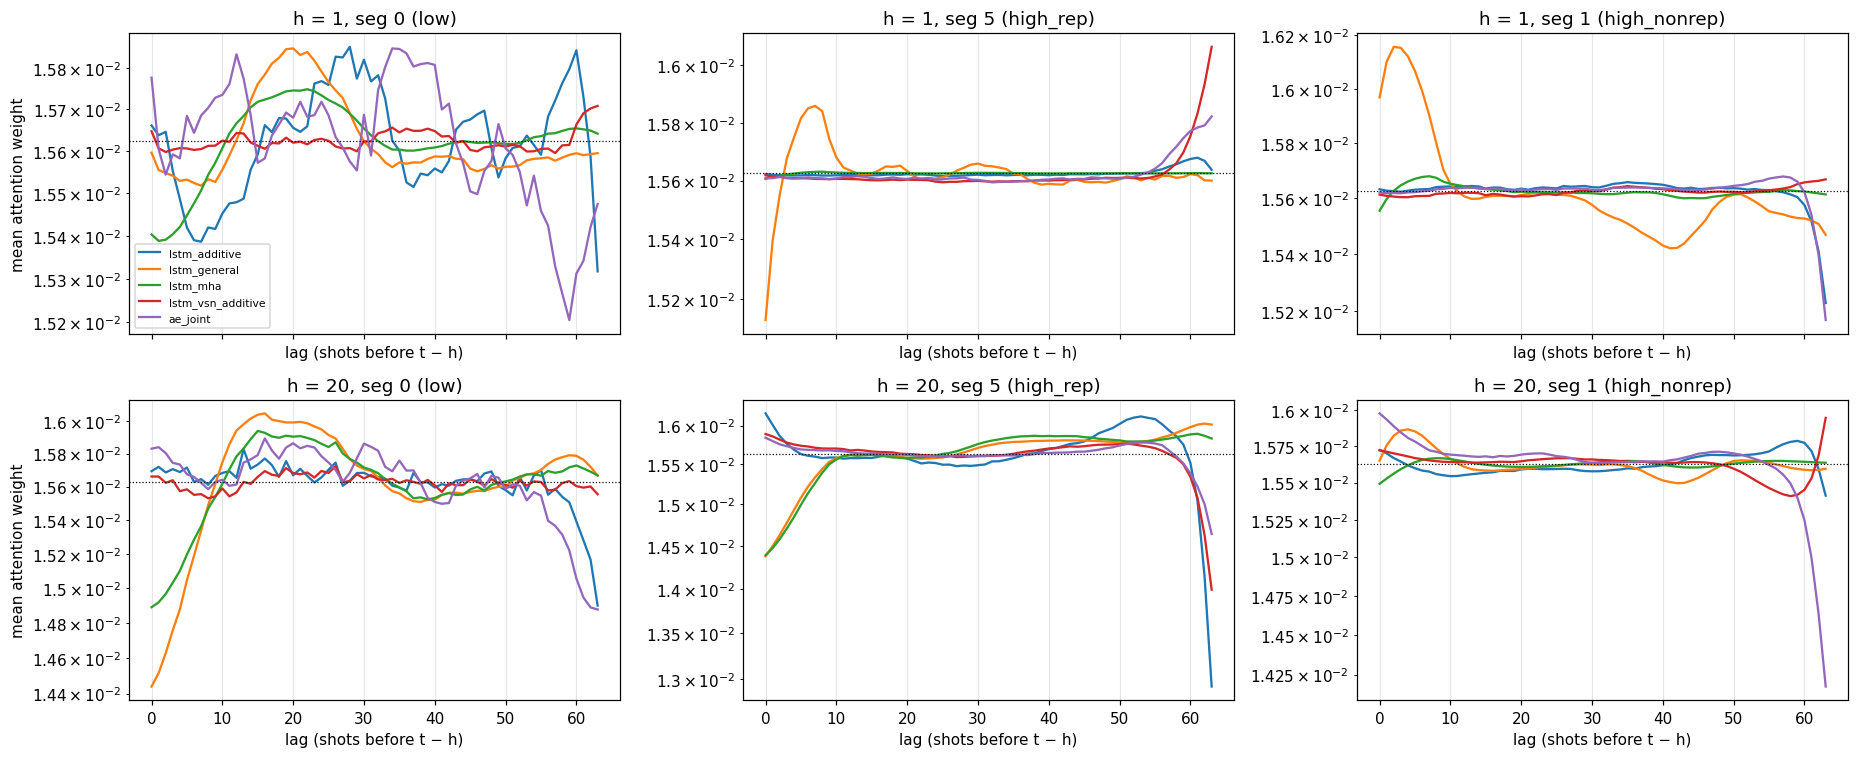

seg                    seg0  seg1  seg2  seg3  seg4  seg5  seg6  seg7
variant           h                                                  
ae_frozen         h1   64.0  64.0  61.7  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  62.2  64.0  64.0  64.0  64.0  64.0
                  h20  64.0  63.9  61.8  64.0  63.9  64.0  64.0  63.9
                  h5   64.0  64.0  62.0  64.0  63.9  64.0  64.0  64.0
                  h50  63.8  63.9  59.6  63.9  63.8  63.7  63.9  63.9
ae_joint          h1   64.0  64.0  61.8  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  62.1  64.0  64.0  64.0  64.0  64.0
                  h20  64.0  64.0  63.2  64.0  64.0  64.0  64.0  64.0
                  h5   64.0  64.0  62.2  64.0  64.0  64.0  64.0  64.0
                  h50  63.9  63.9  59.7  63.9  63.9  63.4  64.0  64.0
lstm_additive     h1   64.0  64.0  61.4  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  62.7  64.0  64.0  64.0  64.0  64.0
                  h20  64.0  64.0  63.9  64.0  63.9  63.9  64.0  64.0
                  h5   64.0  64.0  63.5  64.0  64.0  64.0  64.0  64.0
                  h50  64.0  64.0  62.9  64.0  63.8  64.0  64.0  64.0
lstm_general      h1   64.0  64.0  64.0  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  63.8  63.9  63.9  64.0  64.0  64.0
                  h20  64.0  64.0  64.0  63.8  63.9  64.0  64.0  64.0
                  h5   64.0  64.0  63.9  64.0  63.9  64.0  64.0  64.0
                  h50  63.9  64.0  64.0  63.8  63.8  64.0  64.0  64.0
lstm_mha          h1   64.0  64.0  64.0  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  63.9  64.0  64.0  64.0  64.0  64.0
                  h20  64.0  64.0  64.0  63.9  64.0  64.0  64.0  64.0
                  h5   64.0  64.0  64.0  64.0  64.0  64.0  64.0  64.0
                  h50  64.0  64.0  64.0  64.0  64.0  64.0  64.0  64.0
lstm_vsn_additive h1   64.0  64.0  64.0  64.0  64.0  64.0  64.0  64.0
                  h10  64.0  64.0  62.4  64.0  64.0  64.0  64.0  64.0
                  h20  64.0  64.0  63.8  64.0  64.0  64.0  64.0  64.0
                  h5   64.0  64.0  63.8  64.0  64.0  64.0  64.0  64.0
                  h50  64.0  64.0  63.1  64.0  63.7  63.9  64.0  64.0

In [6]:
I = {}
for p in sorted((R / "attention").glob("interpret_L64_h*.json")):
    I.update(json.loads(p.read_text()))
fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharex=True)
for row, h in enumerate([1, 20]):
    for ax, s in zip(axes[row], (0, 5, 1)):
        for v in ("lstm_additive", "lstm_general", "lstm_mha", "lstm_vsn_additive", "ae_joint"):
            k = f"attn|h{h}|seg{s}|{v}"
            if k in I:
                a = np.array(I[k]); ax.plot(np.arange(len(a))[::-1], a, label=v)
        ax.axhline(1 / 64, color="k", ls=":", lw=0.8); ax.set_yscale("log")
        ax.set_title(f"h = {h}, seg {s} ({segs[s]['regime']})"); ax.set_xlabel("lag (shots before t − h)")
axes[0, 0].set_ylabel("mean attention weight"); axes[1, 0].set_ylabel("mean attention weight"); axes[0, 0].legend(fontsize=7)
fig.tight_layout(); plt.show()
eff = {k: 1 / np.sum(np.array(v) ** 2) for k, v in I.items() if k.startswith("attn|")}
e = pd.Series(eff).rename("effective number of shots attended").to_frame()
e[["kind", "h", "seg", "variant"]] = pd.Series(eff.keys()).str.split("|", expand=True).values
e.pivot_table(index=["variant", "h"], columns="seg", values="effective number of shots attended").round(1)

## 4. Which inputs does the variable-selection network pick?

Mean softmax weight per input (× 29, so 1 = uniform) on the test shots, `lstm_vsn_additive`.

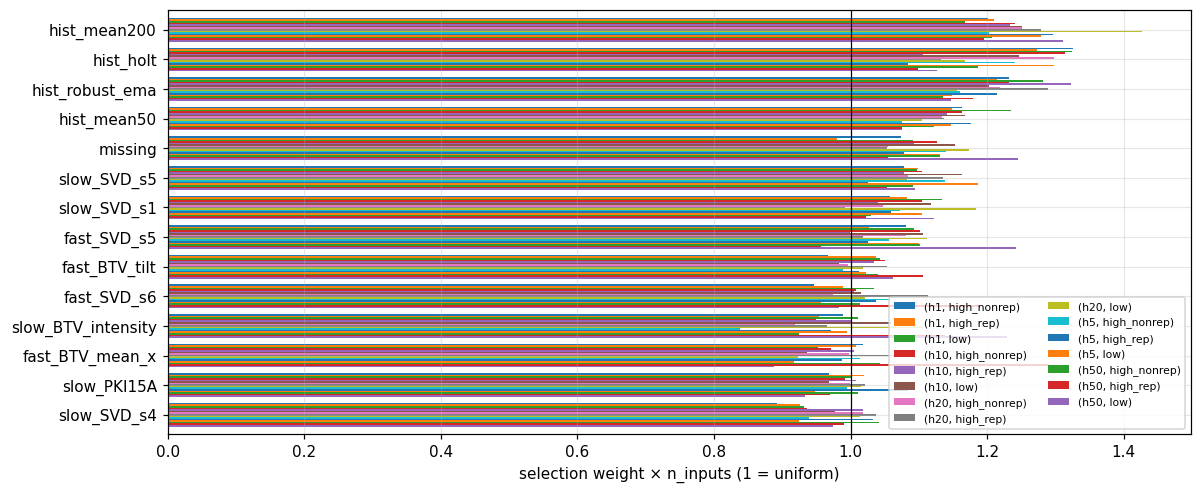

In [7]:
V = {k: v for k, v in I.items() if k.startswith("vsn|")}
vs = pd.DataFrame({k.split("|", 1)[1]: v for k, v in V.items()}).T * 29
vs.index = pd.MultiIndex.from_tuples([tuple(i.split("|")[:2]) for i in vs.index], names=["h", "seg"])
per_reg = vs.groupby(lambda i: (i[0], segs[int(i[1][3:])]["regime"])).mean().T
top = per_reg.mean(1).sort_values(ascending=False).index[:14]
fig, ax = plt.subplots(figsize=(12, 5))
per_reg.loc[top].plot.barh(ax=ax, width=0.8); ax.axvline(1, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("selection weight × n_inputs (1 = uniform)"); ax.legend(fontsize=7, ncol=2); plt.show()

## 5. The autoencoders

Reconstruction error of the inputs (standardised, so 1 = no better than predicting the mean) and what the forecast does
with the codes.

In [8]:
cols = [c for c in A.columns if c.endswith("mse")]
A[A.model.isin(["ae_frozen", "ae_joint", "seq_ae"])].groupby(["model", "h"])[cols + ["mae_pct", "sec_per_fit", "epochs"]].mean().round(3)

ae_recon_mse  seq_recon_mse  mae_pct  sec_per_fit  epochs
model     h                                                            
ae_frozen 1          0.234            NaN    5.463        2.765  25.095
          5          0.230            NaN    5.578        2.684  23.571
          10         0.230            NaN    5.618        2.716  22.810
          20         0.235            NaN    5.705        2.573  21.667
          50         0.226            NaN    6.017        2.672  23.095
ae_joint  1          0.234            NaN    5.455        3.263  24.524
          5          0.230            NaN    5.560        3.367  24.667
          10         0.230            NaN    5.597        3.176  22.238
          20         0.235            NaN    5.697        3.093  22.286
          50         0.226            NaN    5.984        3.248  23.810
seq_ae    1            NaN          0.768    5.471        2.389  21.048
          5            NaN          0.773    5.559        2.478  21.095
          10           NaN          0.770    5.610        2.483  20.381
          20           NaN          0.781    5.690        2.384  19.714
          50           NaN          0.769    6.006        2.586  22.762

## 6. Context length

`lstm`, `lstm_additive`, `lstm_mha`, `ae_joint` with L = 16, 64, 256 at h = 1 and 10.

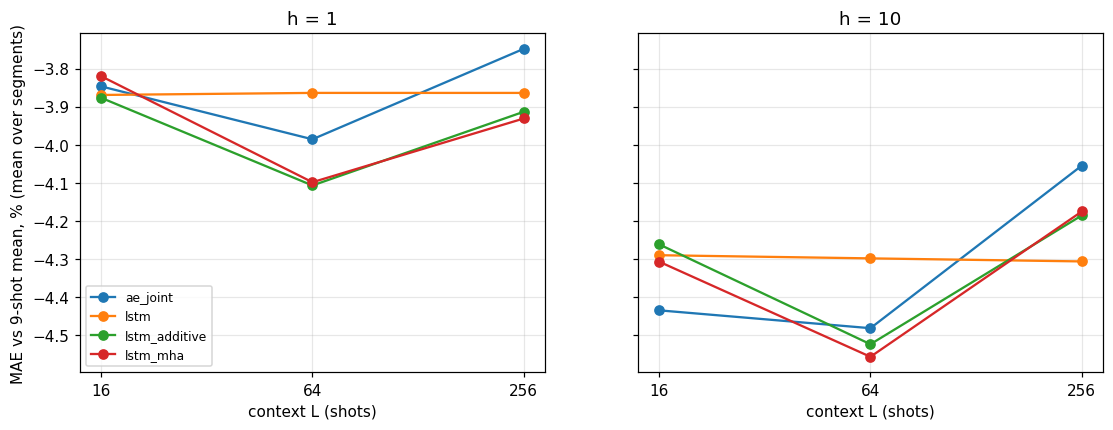

L                  16    64    256
h  model                          
1  ae_joint      -3.85 -3.99 -3.75
   lstm          -3.87 -3.86 -3.86
   lstm_additive -3.88 -4.11 -3.91
   lstm_mha      -3.82 -4.10 -3.93
10 ae_joint      -4.43 -4.48 -4.05
   lstm          -4.29 -4.30 -4.31
   lstm_additive -4.26 -4.52 -4.19
   lstm_mha      -4.31 -4.56 -4.18

L
16     2.0
64     2.1
256    2.4
Name: seconds per fit, dtype: float64

In [9]:
sw = pd.concat([pd.read_csv(p) for p in sorted((R / "attention").glob("scores_L*_sweep.csv"))] +
               [A[(A.h.isin([1, 10])) & A.model.isin(["lstm", "lstm_additive", "lstm_mha", "ae_joint"])]])
sw = sw.merge(base.rename("base").reset_index(), on=["h", "segment"])
sw["vs_mean9_pct"] = 100 * (sw.mae_nC / sw.base - 1)
piv = sw.groupby(["h", "model", "L"]).vs_mean9_pct.mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, h in zip(axes, (1, 10)):
    for m in piv.loc[h].index:
        ax.plot(piv.columns, piv.loc[(h, m)], "o-", label=m)
    ax.set_xscale("log", base=2); ax.set_xticks(piv.columns, piv.columns); ax.set_title(f"h = {h}"); ax.set_xlabel("context L (shots)")
axes[0].set_ylabel("MAE vs 9-shot mean, % (mean over segments)"); axes[0].legend(fontsize=8); plt.show()
display(piv.round(2))
sw.groupby(["L"]).sec_per_fit.mean().round(1).rename("seconds per fit")

## 7. Findings

The cell below prints the numbers the conclusions rest on; the text after it is the reading.

In [10]:
best_h = mean_over.loc[VARS].idxmin()
print("best variant per horizon (mean over segments):", dict(best_h))
print("gap best variant - GRU (points of % vs mean9):", (mean_over.loc[VARS].min() - mean_over.loc["gru L=32, all"]).round(2).to_dict())
print("gap best variant - ridge (points):", (mean_over.loc[VARS].min() - mean_over.loc["ridge, all"]).round(2).to_dict())

best variant per horizon (mean over segments): {1: 'lstm_additive', 5: 'lstm_self', 10: 'lstm_self', 20: 'lstm_general', 50: 'lstm'}
gap best variant - GRU (points of % vs mean9): {1: -0.14, 5: -0.19, 10: -0.2, 20: -1.04, 50: -0.13}
gap best variant - ridge (points): {1: -0.15, 5: -0.12, 10: -0.16, 20: -0.82, 50: -0.67}


## Findings

**1. Attention and autoencoders do not change the picture: forecasting is limited by the data, not the architecture.**
All nine variants land within ~0.5 points of the GRU and the ridge (all beat the 9-shot mean by ~4–5 % on average).
Against the GRU, the best variant by rank (`lstm_mha`) is significantly better in only 11 % of the (segment, horizon)
cases, and significantly worse in none. The one place with a visible gain is h = 20, where the attention LSTMs
(additive / general / MHA) are ~1 point better than the GRU on average, significant on segs 1 and 6.

**2. Ranking.** Mean rank over 35 (segment, horizon) cases: LSTM + MHA 4.3, + general 4.6, + additive 4.7 —
the attention readouts are consistently a little ahead of the plain LSTM (5.9), the GRU (6.1) and the ridge (6.2).
Self-attention, variable selection and every autoencoder variant rank below the plain LSTM.

**3. The attention learns an average, not a focus.** Mean weights stay within ~5 % of uniform (1/64) at every lag,
in every regime and horizon; the "effective number of shots attended" is ~64. The small gain over the plain LSTM is
therefore a learned window average read alongside the last state, not the discovery of specific informative lags.
This fits the earlier results: on stable beam the remaining error is white, laser-driven jitter, and the useful
history is a smooth level.
(Caveat: these are mean profiles over the test shots; per-shot attention could be sharper and still average out.)

**4. Inputs that matter for forecasting are the BCM history, not the instruments.** The variable-selection network
up-weights the 200- and 50-shot charge means, Holt and the robust EMA (1.2–1.3 × uniform) in every regime; slow camera
SVD parts get a little weight; all fast instrument parts stay at or below uniform. Nothing fast predicts the future.

**5. Autoencoders.** A per-shot autoencoder compresses the 29 inputs to 8 with 23 % reconstruction error, and the
sequence autoencoder reconstructs the window poorly (77 %). Neither embedding helps: `ae_joint` ≈ plain LSTM,
`ae_frozen` and `seq_ae` rank last. The inputs are already low-dimensional and the forecast needs only a handful of
them, so compression only removes information.

**6. Context length.** L = 64 is best for the attention variants; L = 256 costs ~0.3 points and L = 16 ~0.2. The plain
LSTM is insensitive (as the GRU was). Training is cheap: 2–3 s per fit on a GB200, ~20 epochs with early stopping.

**Recommendation.** For deployment, an LSTM with an additive or multi-head attention readout over 64 shots is a
small, consistent improvement over the GRU, mostly at 10–20 shots ahead; the autoencoder front-ends are not worth it.
The larger gains remain where the instruments see the shot itself (virtual diagnostic, notebooks 13 and 15).